# Decision Tree

A single decision tree: a flowchart of yes/no questions on feature thresholds (e.g. "is `same_srv_rate` ≤ 0.3?"), learned by picking at each step the split that best separates normal from DoS rows (Gini impurity). Thresholds don't care about scale, so no scaling is needed.

It is the building block of Random Forest (notebook 04). Defined in `src/dosdetect/models.py` as `decision_tree()`; grown to full depth by default.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

Normal and DoS traffic only (`dosdetect.data.prepare_all`). Six setups, three splits at two feature counts:

- **official**: NSL-KDD, train on `KDDTrain+`, test on `KDDTest+`. A share of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm); the count is printed below.
- **holdout**: NSL-KDD, stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **kddcup**: KDDCup'99 (10% file), stratified 80/20 split. The labelled KDDCup test file is no longer downloadable, so there is no official split for this dataset.
- **8 features** (top 8 by |Spearman correlation| with the label, our reading of the paper's filter) or **all 41**. On KDDCup this ranking reproduces the features the paper names (`dst_bytes`, `protocol_type`, the connection counts); on NSL-KDD it does not (see the README). The table below shows the NSL-KDD top 8.

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print(
    "Unseen DoS rows in official test:",
    official["unseen"].sum(),
    "of",
    int(official["y_test"].sum()),
    "DoS rows",
)
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717 of 7458 DoS rows


,|correlation| with label
same_srv_rate,0.8433
flag,0.7974
diff_srv_rate,0.7747
serror_rate,0.7712
srv_serror_rate,0.7686
dst_host_serror_rate,0.7485
dst_host_srv_serror_rate,0.7410
count,0.7366


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["decision_tree"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8497,0.9279,0.7092,0.8039,0.8652,0.1875,0.1937,0.0087
"official, 41 features",0.9133,0.9651,0.8305,0.8928,0.9868,0.3081,1.0448,0.0016
"holdout, 8 features",0.9728,0.9920,0.9404,0.9655,NaN,NaN,0.0679,0.0017
"holdout, 41 features",0.9997,0.9996,0.9997,0.9996,NaN,NaN,0.6168,0.0093
"kddcup, 8 features",0.9994,0.9998,0.9994,0.9996,NaN,NaN,0.4636,0.0117
"kddcup, 41 features",0.9999,0.9999,1.0000,0.9999,NaN,NaN,1.0404,0.0115


### Confusion matrices

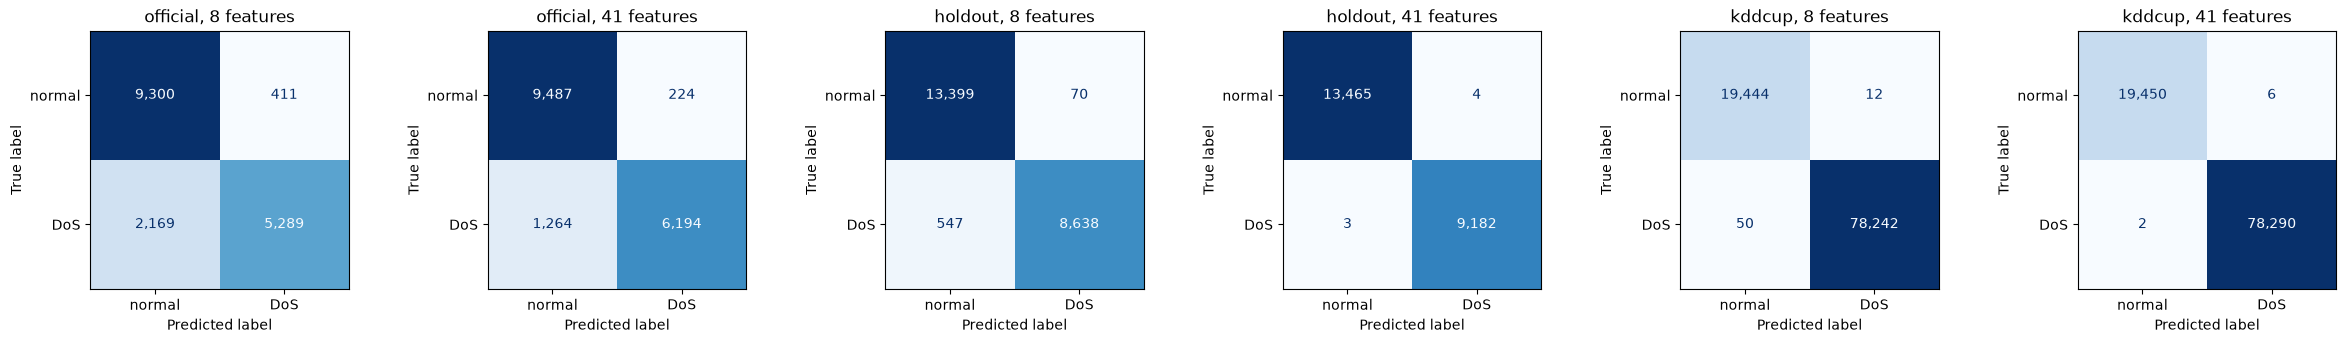

In [4]:
plot_confusions(results);

## Tree depth

A full-depth tree can memorise the training data. Limiting depth makes it simpler. 8 features.

,official,holdout,kddcup
max_depth,,,
2,0.8258,0.9608,0.9899
4,0.8282,0.9700,0.9967
6,0.8329,0.9726,0.9979
8,0.8321,0.9734,0.9987
10,0.8472,0.9740,0.9991
15,0.8607,0.9734,0.9994
20,0.8577,0.9728,0.9994
None,0.8497,0.9728,0.9994


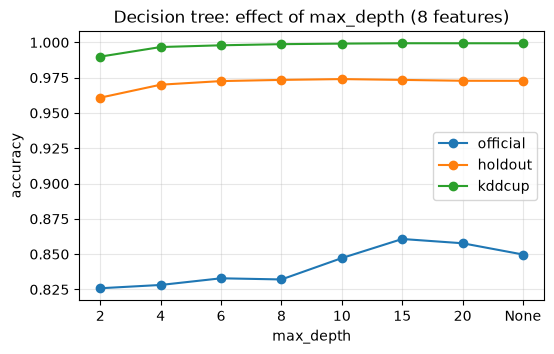

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

depths = [2, 4, 6, 8, 10, 15, 20, None]
depth_table = pd.DataFrame(
    {
        split: [
            evaluate(DecisionTreeClassifier(max_depth=d, random_state=42), data[(split, 8)])[
                "accuracy"
            ]
            for d in depths
        ]
        for split in ("official", "holdout", "kddcup")
    },
    index=pd.Index([str(d) for d in depths], name="max_depth"),
)
ax = depth_table.plot(marker="o", figsize=(6, 3.5))
ax.set(ylabel="accuracy", title="Decision tree: effect of max_depth (8 features)")
ax.grid(alpha=0.3)
depth_table

## What the tree learned

The top three levels of the full tree (official training data, 8 features), and how much each feature contributes.

Depth: 28  Leaves: 879


,importance
same_srv_rate,0.8124
count,0.0675
flag,0.0672
dst_host_serror_rate,0.0404
serror_rate,0.0056
dst_host_srv_serror_rate,0.0046
diff_srv_rate,0.0012
srv_serror_rate,0.0011


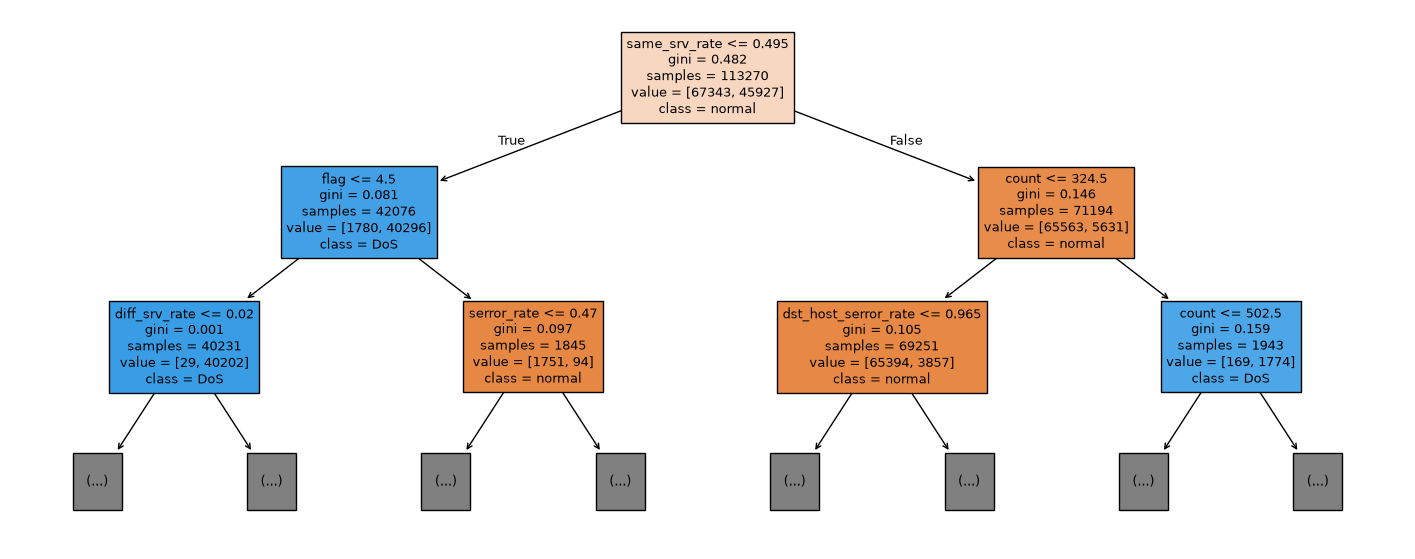

In [6]:
tree = MODELS["decision_tree"]().fit(official["X_train"], official["y_train"])
print("Depth:", tree.get_depth(), " Leaves:", tree.get_n_leaves())
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    tree,
    max_depth=2,
    feature_names=list(official["X_train"].columns),
    class_names=["normal", "DoS"],
    filled=True,
    fontsize=9,
    ax=ax,
)
pd.Series(tree.feature_importances_, official["X_train"].columns, name="importance").sort_values(
    ascending=False
).to_frame()

## Cost against the forest

Training-time ratio of Random Forest (`MODELS["random_forest"]`) to this single tree, 8 and 41 features, official split.

In [7]:
forest = {n: evaluate(MODELS["random_forest"](), data[("official", n)]) for n in (8, 41)}
pd.Series(
    {
        f"{n} features": forest[n]["train_time_s"] / results[("official", n)]["train_time_s"]
        for n in (8, 41)
    },
    name="forest train time / tree",
).round(0).to_frame()

,forest train time / tree
8 features,41.0
41 features,9.0


## Takeaways

- **Near-perfect on KDDCup and the NSL-KDD holdout, much worse on the official file.** With 8 features accuracy is 99.9% on kddcup, 97.3% on holdout and 85.0% on official; recall on official is 70.9%. The weak spot is the official test file, not the model.
- **Unseen attacks are still the weak spot**: 18.8% recall on never-seen DoS types with 8 features and 30.8% with 41 features, against 86.5% and 98.7% on seen types. The tree learns thresholds that fit known attacks and has no reason to flag traffic outside them.
- **More features help on the official file.** Going from 8 to 41 features raises official accuracy from 85.0% to 91.3% and recall from 70.9% to 83.1%.
- **Depth matters little beyond a moderate depth.** On kddcup, accuracy is 99.7% at depth 4 and 99.9% from depth 10 on. On official it peaks at 86.1% (depth 15) and is 85.0% for the full tree, against 83.3% at depth 6. A shallow tree is far easier to read and explain in a forensics report.
- **One feature does most of the work.** `same_srv_rate` (share of recent connections to the same service) has importance 0.81 in the full tree, followed by `count` (0.07) and `flag` (0.07). DoS floods hammer one service, so this is an easy feature to justify to an investigator.
- **Much cheaper than the forest.** In the cost table the forest takes roughly an order of magnitude or more longer to train than one tree at both 8 and 41 features (the ratio is larger at 8 features, and the exact values vary from run to run).